In [11]:
import os
from langchain_openai import ChatOpenAI
from dotenv import load_dotenv
from langchain_tavily import TavilySearch
from langchain_core.prompts import PromptTemplate,ChatPromptTemplate,MessagesPlaceholder
from langchain_core.output_parsers import StrOutputParser
from langchain_core.messages import SystemMessage,HumanMessage
from langgraph.graph import StateGraph,START,END,MessagesState
from langgraph.prebuilt import ToolNode,tools_condition
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.graph.message import add_messages
load_dotenv()

True

In [12]:
llm=ChatOpenAI(model='gpt-5.4-mini')

try:
    tavily_key=os.getenv('TAVILY_API_KEY')
except:
    print('Api key Missing')

In [13]:
search_tool=TavilySearch(api_key=tavily_key,max_results=10,search_depth='advanced')


tools = [search_tool]
tool_node = ToolNode(tools)

In [14]:
agentic_llm=llm.bind_tools(tools)

In [15]:
from langchain_core.messages import SystemMessage
def ask_llm(state:MessagesState):
   query=state['messages']
   sys_msg=SystemMessage(content="""

    You are an Expert AI assistant:\n
        - Answer the user's request using your parametric knowledge if available, otherwise rely on tools.\n"
        - The answer should be clean, polite, respectful, and MUST NOT contain markdown formatting like ** or ###."
    """)

   chain=llm 
   response=chain.invoke([sys_msg] + query)
   return {'messages':response}
   

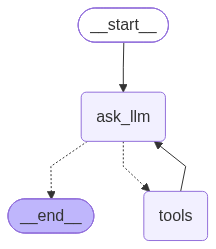

In [16]:

checkpointer=InMemorySaver()
config={'configurable':{'thread_id':'1234'}}
graph=StateGraph(MessagesState)

graph.add_node('ask_llm', ask_llm)
graph.add_node('tools',tool_node)

graph.add_edge(START,'ask_llm')
graph.add_conditional_edges('ask_llm',tools_condition)
graph.add_edge('tools','ask_llm')

chatbot=graph.compile(checkpointer=checkpointer) #type:ignore
chatbot



In [17]:
result=chatbot.invoke({'messages':
    [HumanMessage( 
        content='Latest AI news in the week any 5')]},config=config) #type:ignore

In [19]:
result

{'messages': [HumanMessage(content='Latest AI news in the week any 5', additional_kwargs={}, response_metadata={}, id='20379da3-7ae1-4ef7-8cc6-eb583f150256'),
  AIMessage(content='Here are 5 notable AI news items from the past week, in a simple summary format:\n\n1. OpenAI expanded ChatGPT features\nOpenAI rolled out updates to ChatGPT, improving voice interactions, memory, and tool use for more natural conversations and better task handling.\n\n2. Google DeepMind announced new model progress\nDeepMind highlighted advances in reasoning and multimodal AI, with stronger performance on complex tasks like coding, science, and image understanding.\n\n3. NVIDIA continued pushing AI hardware\nNVIDIA introduced or teased new GPU and AI infrastructure improvements aimed at training and running larger models faster and more efficiently.\n\n4. Microsoft added more AI features to its products\nMicrosoft expanded Copilot-style AI integration across Windows, Office, and developer tools to make AI as

In [20]:
print(result['messages'][-1].content)

Here are 5 notable AI news items from the past week, in a simple summary format:

1. OpenAI expanded ChatGPT features
OpenAI rolled out updates to ChatGPT, improving voice interactions, memory, and tool use for more natural conversations and better task handling.

2. Google DeepMind announced new model progress
DeepMind highlighted advances in reasoning and multimodal AI, with stronger performance on complex tasks like coding, science, and image understanding.

3. NVIDIA continued pushing AI hardware
NVIDIA introduced or teased new GPU and AI infrastructure improvements aimed at training and running larger models faster and more efficiently.

4. Microsoft added more AI features to its products
Microsoft expanded Copilot-style AI integration across Windows, Office, and developer tools to make AI assistance more available in everyday workflows.

5. AI regulation discussions advanced
Governments and regulators in multiple regions continued debating AI safety, copyright, transparency, and 

In [21]:
result['messages'][-1].usage_metadata

{'input_tokens': 72,
 'output_tokens': 235,
 'total_tokens': 307,
 'input_token_details': {'audio': 0, 'cache_read': 0},
 'output_token_details': {'audio': 0, 'reasoning': 0}}